# EDA — Siniestralidad Peatonal en Bogotá D.C. (Unión de fuentes)

Este cuaderno une y analiza dos fuentes de datos abiertos sobre siniestralidad vial en Bogotá D.C.:

1. **`DATO_ABIERTOS_siniestros_viales_consolidados_bogota_dc (3).xlsx`** — archivo oficial "Datos Abiertos" con 5 hojas relacionales: `SINIESTROS`, `ACTOR_VIAL`, `VEHICULOS`, `HIPOTESIS` y `DICCIONARIO` (codificación de valores).
2. **`historico_siniestros_bogota_d_c_-.csv`** — histórico consolidado de siniestros con coordenadas geográficas (`LATITUD`, `LONGITUD`).

Ambas fuentes comparten la llave **`CODIGO_ACCIDENTE`**, que identifica un siniestro. Se usa para:
- Unir el histórico georreferenciado (CSV) con el detalle oficial del siniestro (hoja `SINIESTROS`).
- Enriquecer cada siniestro con información agregada de actores viales, vehículos involucrados y causas (hipótesis), agregadas desde las otras hojas del Excel.

Estructura del cuaderno:

1. Diccionario de variables (CSV y cada hoja del Excel)
2. Carga de datos
3. Preparación y unión de los datasets por `CODIGO_ACCIDENTE`
4. EDA general del dataset unido
5. Análisis temporal
6. Análisis por gravedad, clase, causas y actores
7. Mapa de zonas con accidentes
8. Resumen y hallazgos clave


> **Nota de alcance (corrección):** el EDA (secciones 4 en adelante) se ejecuta sobre `df_peatones`, el subconjunto de siniestros donde participó al menos un **peatón** según `ACTOR_VIAL.CONDICION == 'PEATON'`. La sección 3 sigue construyendo primero el dataset general (`df`, todos los siniestros) porque de ahí se filtra.


## 1. Diccionario de variables

### 1.1 `historico_siniestros_bogota_d_c_-.csv`

199.146 registros. Un registro = un siniestro georreferenciado.

| Variable | Tipo | Descripción |
|---|---|---|
| `X` | float | Coordenada X (idéntica a `LONGITUD`), grados decimales EPSG:4326. |
| `Y` | float | Coordenada Y (idéntica a `LATITUD`), grados decimales EPSG:4326. |
| `OBJECTID` | int | Identificador interno del registro en el sistema de origen. |
| `FORMULARIO` | str | Número del formulario / acta policial (FURIPS/IPAT) asociado al siniestro. |
| `CODIGO_ACCIDENTE` | int | **Llave de unión.** Identificador único del siniestro, compartido con el archivo Excel. |
| `FECHA_OCURRENCIA_ACC` | str/fecha | Fecha en que ocurrió el siniestro. |
| `ANO_OCURRENCIA_ACC` | int | Año de ocurrencia (2015–2021). |
| `DIRECCION` | str | Dirección / nomenclatura vial donde ocurrió el siniestro. |
| `GRAVEDAD` | str | Gravedad del siniestro: `SOLO DAÑOS`, `CON HERIDOS`, `CON MUERTOS`. |
| `CLASE_ACC` | str | Clase de siniestro: `CHOQUE`, `ATROPELLO`, `CAIDA DE OCUPANTE`, `VOLCAMIENTO`, `OTRO`, `INCENDIO`, `AUTOLESION`. |
| `LOCALIDAD` | str | Localidad de Bogotá donde ocurrió el siniestro (46 nulos). |
| `FECHA_HORA_ACC` | str/fecha-hora | Fecha y hora completa del siniestro. |
| `LATITUD` | float | Latitud del siniestro (EPSG:4326). |
| `LONGITUD` | float | Longitud del siniestro (EPSG:4326). |
| `CIV` | float | Código de Identificación Vial del segmento donde ocurrió (1.701 nulos). |
| `PK_CALZADA` | float | Punto kilométrico sobre la calzada (37.974 nulos, alta tasa de faltantes). |

### 1.2 `SINIESTROS` (hoja del Excel)

196.152 registros. Nivel de detalle: un siniestro. Los códigos se decodifican usando la hoja `DICCIONARIO` del mismo archivo.

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | **Llave de unión** con el CSV. |
| `FECHA` | str/fecha | Fecha de ocurrencia. |
| `HORA` | str | Hora de ocurrencia. |
| `GRAVEDAD` | int | Código de gravedad: `1`=Con Muertos, `2`=Con Heridos, `3`=Solo Daños. |
| `CLASE` | int | Código de clase de siniestro: `1`=Choque, `2`=Atropello, `3`=Volcamiento, `4`=Caída de ocupante, `5`=Incendio, `6`=Otro, `7`=Autolesión. |
| `CHOQUE` | float | Tipo de objeto contra el que se chocó (solo aplica si `CLASE`=Choque): `1`=Vehículo, `2`=Tren, `3`=Semoviente, `4`=Objeto Fijo. |
| `OBJETO_FIJO` | float | Detalle del objeto fijo golpeado (solo si `CHOQUE`=4): Muro, Poste, Árbol, Barandas, Semáforo, Inmueble, Hidrante, Valla/Señal, Tarima/Caseta, Vehículo estacionado, Otro. |
| `DIRECCION` | str | Dirección del siniestro. |
| `CODIGO_LOCALIDAD` | int | Código numérico de la localidad (1–20, incluye Sumapaz). |
| `DISENO_LUGAR` | int | Diseño del lugar donde ocurrió: Tramo de Vía, Intersección, Vía peatonal, Paso elevado/inferior/a nivel, Glorieta, Puente, Vía troncal, Lote/predio, Ciclorruta, Pontón, Túnel. |

### 1.3 `ACTOR_VIAL` (hoja del Excel)

422.417 registros. Nivel de detalle: una persona involucrada en un siniestro (varias por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | Llave que vincula al siniestro. |
| `CODIGO_ACCIDENTADO` | int | Identificador de la persona involucrada. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `CONDICION` | str | Rol de la persona: `CONDUCTOR`, `MOTOCICLISTA`, `PASAJERO/ACOMPAÑANTE`, `PEATON`, `CICLISTA`. |
| `ESTADO` | str | Estado de la persona tras el siniestro: `ILESO`, `HERIDO`, `MUERTO`. |
| `EDAD` | object | Edad de la persona (contiene inconsistencias de formato, se trata como texto en la fuente). |
| `SEXO` | str | Sexo reportado: `MASCULINO`, `FEMENINO`, `SIN INFORMACION`. |
| `VEHICULO` | str | Código del vehículo asociado (nulo para peatones — 23.447 nulos, coincide con el conteo de peatones). |

### 1.4 `VEHICULOS` (hoja del Excel)

371.606 registros. Nivel de detalle: un vehículo involucrado en un siniestro (varios por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | Llave que vincula al siniestro. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `VEHICULO` | str | Identificador del vehículo (formato `CODIGO_ACCIDENTE-n`). |
| `CLASE` | int | Clase de vehículo (27 categorías): Automóvil, Bus, Buseta, Camión/Furgón, Camioneta, Campero, Microbús, Motocicleta, Bicicleta, Bus Articulado, entre otros. |
| `SERVICIO` | int | Tipo de servicio del vehículo: `1`=Oficial, `2`=Público, `3`=Particular, `4`=Diplomático, `0`=Sin información. |
| `MODALIDAD` | int | Modalidad de transporte (Mixto, Carga, Pasajeros — Masivo/Colectivo/Individual/Escolar, etc.). |
| `ENFUGA` | str | Indica si el vehículo se dio a la fuga: `S`/`N`. |

### 1.5 `HIPOTESIS` (hoja del Excel)

233.820 registros. Nivel de detalle: una causa/hipótesis asociada a un siniestro (varias posibles por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | Llave que vincula al siniestro. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `CODIGO_CAUSA` | int | Código de causa probable del siniestro (~150 categorías agrupadas por actor: conductor en general, ciclista/motociclista, vehículo, vía, peatón, pasajero/acompañante). Ej.: `116`=Exceso de velocidad, `115`=Embriaguez o droga, `142`=Semáforo en rojo, `306`=Huecos, `409`=Cruzar sin observar. |

### 1.6 `DICCIONARIO` (hoja del Excel)

212 filas. Tabla de codificación oficial: `HOJA`, `CAMPO`, `CODIGO`, `DESCRIPCION`. Se usa programáticamente en este cuaderno para traducir todos los códigos numéricos anteriores a sus etiquetas de texto.


## 2. Carga de librerías y datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (9, 6)


In [2]:
FILE_XLSX = "Data/raw/DATO_ABIERTOS_siniestros_viales_consolidados_bogota_dc (3).xlsx"
FILE_CSV = "Data/raw/historico_siniestros_bogota_d_c_-.csv"

# Histórico georreferenciado
hist = pd.read_csv(FILE_CSV, encoding='utf-8-sig')

# Hojas del archivo oficial
siniestros = pd.read_excel(FILE_XLSX, sheet_name='SINIESTROS')
actor_vial = pd.read_excel(FILE_XLSX, sheet_name='ACTOR_VIAL')
vehiculos  = pd.read_excel(FILE_XLSX, sheet_name='VEHICULOS')
hipotesis  = pd.read_excel(FILE_XLSX, sheet_name='HIPOTESIS')
diccionario = pd.read_excel(FILE_XLSX, sheet_name='DICCIONARIO')

print("historico_siniestros (CSV):", hist.shape)
print("SINIESTROS   :", siniestros.shape)
print("ACTOR_VIAL   :", actor_vial.shape)
print("VEHICULOS    :", vehiculos.shape)
print("HIPOTESIS    :", hipotesis.shape)
print("DICCIONARIO  :", diccionario.shape)


historico_siniestros (CSV): (199146, 16)
SINIESTROS   : (196152, 10)
ACTOR_VIAL   : (422416, 8)
VEHICULOS    : (371605, 7)
HIPOTESIS    : (233819, 3)
DICCIONARIO  : (211, 4)


### 2.1 Vista previa de cada tabla

In [3]:
hist.head()

,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0


In [4]:
siniestros.head()

,CODIGO_ACCIDENTE,FECHA,HORA,GRAVEDAD,CLASE,CHOQUE,OBJETO_FIJO,DIRECCION,CODIGO_LOCALIDAD,DISENO_LUGAR
0,4401438,01/01/2015,01:05:00,2,2,NaN,NaN,KR 64A-CL 2C 02,16,2
1,4401449,01/01/2015,05:50:00,2,3,NaN,NaN,AV AVENIDA DEL SUR-KR 65A 41,7,1
2,4401430,01/01/2015,07:15:00,2,3,NaN,NaN,KR 19D-CL 62 S 02,19,1
3,4401453,01/01/2015,09:30:00,3,1,1.0,NaN,KR 79-CL 42F S 71,8,1
4,4401423,01/01/2015,09:45:00,2,1,1.0,NaN,CL 66A-KR 76 02,10,2


In [5]:
diccionario.head(10)

,HOJA,CAMPO,CODIGO,DESCRIPCION
0,SINIESTROS,GRAVEDAD,1,Con Muertos
1,SINIESTROS,GRAVEDAD,2,Con Heridos
2,SINIESTROS,GRAVEDAD,3,Solo Daños
3,SINIESTROS,CLASE,7,Autolesion
4,SINIESTROS,CLASE,1,Choque
5,SINIESTROS,CLASE,2,Atropello
6,SINIESTROS,CLASE,4,Caida de ocupante
7,SINIESTROS,CLASE,3,Volcamiento
8,SINIESTROS,CLASE,6,Otro
9,SINIESTROS,CLASE,5,Incendio


## 3. Preparación y unión de los datasets

### 3.1 Función de decodificación

Se construye un diccionario Python `{{(HOJA, CAMPO): {{codigo: descripcion}}}}` a partir de la hoja `DICCIONARIO`, para traducir los códigos numéricos de `SINIESTROS`, `VEHICULOS` e `HIPOTESIS` a texto legible.

In [6]:
def construir_mapa_diccionario(dicc):
    mapa = {}
    for _, row in dicc.iterrows():
        clave = (row['HOJA'], row['CAMPO'])
        mapa.setdefault(clave, {})[row['CODIGO']] = row['DESCRIPCION']
    return mapa

mapa_dicc = construir_mapa_diccionario(diccionario)

def decodificar(df, hoja, campo, nueva_col=None):
    nueva_col = nueva_col or f"{campo}_DESC"
    mapa = mapa_dicc.get((hoja, campo), {})
    df[nueva_col] = df[campo].map(mapa)
    return df

# Decodificar SINIESTROS
siniestros = decodificar(siniestros, 'SINIESTROS', 'GRAVEDAD')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CLASE')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CHOQUE')
siniestros = decodificar(siniestros, 'SINIESTROS', 'OBJETO_FIJO')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CODIGO_LOCALIDAD', 'LOCALIDAD_DESC')
siniestros = decodificar(siniestros, 'SINIESTROS', 'DISENO_LUGAR')

# Decodificar VEHICULOS
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'CLASE')
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'SERVICIO')
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'MODALIDAD')

# Decodificar HIPOTESIS
hipotesis = decodificar(hipotesis, 'HIPOTESIS', 'CODIGO_CAUSA')

siniestros[['GRAVEDAD','GRAVEDAD_DESC','CLASE','CLASE_DESC','DISENO_LUGAR','DISENO_LUGAR_DESC']].head()

,GRAVEDAD,GRAVEDAD_DESC,CLASE,CLASE_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC
0,2,Con Heridos,2,Atropello,2,Interseccion
1,2,Con Heridos,3,Volcamiento,1,Tramo de Via
2,2,Con Heridos,3,Volcamiento,1,Tramo de Via
3,3,Solo Daños,1,Choque,1,Tramo de Via
4,2,Con Heridos,1,Choque,2,Interseccion


### 3.2 Cobertura de la llave `CODIGO_ACCIDENTE` entre fuentes

Antes de unir, se revisa cuántos códigos coinciden entre el CSV histórico y la hoja `SINIESTROS` del Excel.

In [7]:
set_csv = set(hist['CODIGO_ACCIDENTE'])
set_xlsx = set(siniestros['CODIGO_ACCIDENTE'])

interseccion = set_csv & set_xlsx
solo_csv = set_csv - set_xlsx
solo_xlsx = set_xlsx - set_csv

print(f"Códigos únicos en CSV               : {len(set_csv):,}")
print(f"Códigos únicos en SINIESTROS (XLSX)  : {len(set_xlsx):,}")
print(f"En ambas fuentes (intersección)      : {len(interseccion):,}")
print(f"Solo en CSV (sin match en XLSX)      : {len(solo_csv):,}")
print(f"Solo en XLSX (sin match en CSV)      : {len(solo_xlsx):,}")

Códigos únicos en CSV               : 199,146
Códigos únicos en SINIESTROS (XLSX)  : 196,152
En ambas fuentes (intersección)      : 181,020
Solo en CSV (sin match en XLSX)      : 18,126
Solo en XLSX (sin match en CSV)      : 15,132


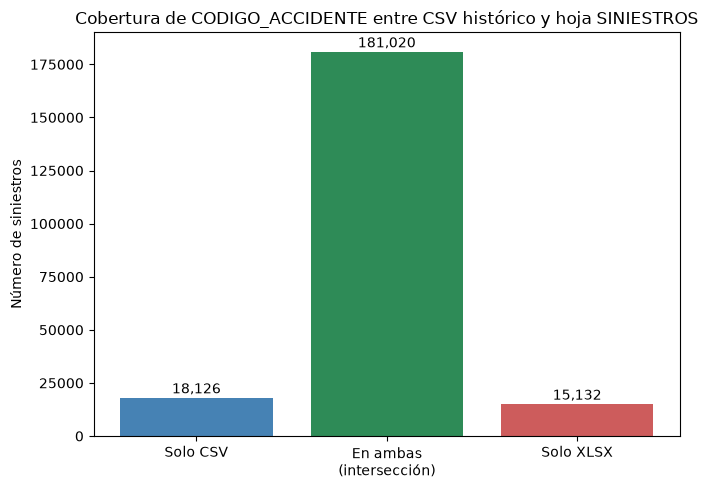

In [8]:
fig, ax = plt.subplots(figsize=(7,5))
labels = ['Solo CSV', 'En ambas\n(intersección)', 'Solo XLSX']
valores = [len(solo_csv), len(interseccion), len(solo_xlsx)]
ax.bar(labels, valores, color=['steelblue', 'seagreen', 'indianred'])
for i, v in enumerate(valores):
    ax.text(i, v + 2000, f"{v:,}", ha='center')
ax.set_title('Cobertura de CODIGO_ACCIDENTE entre CSV histórico y hoja SINIESTROS')
ax.set_ylabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 3.3 Unión principal (CSV + SINIESTROS)

Se usa **`hist` (CSV) como tabla base**, porque es la única que trae coordenadas geográficas (`LATITUD`/`LONGITUD`), indispensables para el mapa. Se hace un `left join` con `SINIESTROS` por `CODIGO_ACCIDENTE`, para incorporar los campos adicionales que no están en el CSV: `CHOQUE`, `OBJETO_FIJO`, `DISENO_LUGAR` y sus descripciones.

In [9]:
cols_siniestros = ['CODIGO_ACCIDENTE', 'CHOQUE', 'CHOQUE_DESC', 'OBJETO_FIJO', 'OBJETO_FIJO_DESC',
                    'DISENO_LUGAR', 'DISENO_LUGAR_DESC']

df = hist.merge(siniestros[cols_siniestros], on='CODIGO_ACCIDENTE', how='left', indicator=True)

print("Registros del CSV con match en SINIESTROS:", (df['_merge'] == 'both').sum())
print("Registros del CSV SIN match en SINIESTROS:", (df['_merge'] == 'left_only').sum())
df = df.drop(columns='_merge')
print("\nShape del dataset unido:", df.shape)
df.head()

Registros del CSV con match en SINIESTROS: 181020
Registros del CSV SIN match en SINIESTROS: 18126

Shape del dataset unido: (199146, 22)


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN,NaN,NaN,NaN,NaN,7.0,Glorieta
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0,1.0,Vehiculo,NaN,NaN,5.0,Paso inferior


### 3.4 Enriquecimiento con actores, vehículos y causas

Se agregan, por `CODIGO_ACCIDENTE`, resúmenes de las otras tres hojas y se incorporan al dataset unido:
- **Actores viales**: número de personas involucradas, número de muertos/heridos, sexo predominante.
- **Vehículos**: número de vehículos involucrados, clase de vehículo más frecuente.
- **Hipótesis**: causa principal reportada (la primera registrada por siniestro).

In [10]:
# Resumen de actores por accidente
agg_actores = actor_vial.groupby('CODIGO_ACCIDENTE').agg(
    N_ACTORES=('CODIGO_ACCIDENTADO', 'count'),
    N_MUERTOS=('ESTADO', lambda s: (s == 'MUERTO').sum()),
    N_HERIDOS=('ESTADO', lambda s: (s == 'HERIDO').sum()),
).reset_index()

# Resumen de vehículos por accidente
agg_vehiculos = vehiculos.groupby('CODIGO_ACCIDENTE').agg(
    N_VEHICULOS=('VEHICULO', 'count'),
).reset_index()
clase_top_vehiculo = (vehiculos.groupby('CODIGO_ACCIDENTE')['CLASE_DESC']
                       .agg(lambda s: s.value_counts().index[0] if len(s.dropna()) else np.nan)
                       .reset_index().rename(columns={'CLASE_DESC': 'CLASE_VEHICULO_PRINCIPAL'}))

# Causa principal por accidente (primera hipótesis registrada)
causa_principal = (hipotesis.sort_values('CODIGO_ACCIDENTE')
                   .groupby('CODIGO_ACCIDENTE')['CODIGO_CAUSA_DESC']
                   .first().reset_index().rename(columns={'CODIGO_CAUSA_DESC': 'CAUSA_PRINCIPAL'}))

df = (df.merge(agg_actores, on='CODIGO_ACCIDENTE', how='left')
        .merge(agg_vehiculos, on='CODIGO_ACCIDENTE', how='left')
        .merge(clase_top_vehiculo, on='CODIGO_ACCIDENTE', how='left')
        .merge(causa_principal, on='CODIGO_ACCIDENTE', how='left'))

print("Shape final del dataset unido y enriquecido:", df.shape)
df.head()

Shape final del dataset unido y enriquecido: (199146, 28)


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC,N_ACTORES,N_MUERTOS,N_HERIDOS,N_VEHICULOS,CLASE_VEHICULO_PRINCIPAL,CAUSA_PRINCIPAL
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via,2.0,0.0,0.0,2.0,Camioneta,No mantener distancia de seguridad (conductor ...
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN,NaN,NaN,NaN,NaN,7.0,Glorieta,1.0,0.0,1.0,1.0,Motocicleta,Otra (conductor en general)
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via,2.0,0.0,0.0,2.0,"Camion, Furgon",Otra (conductor en general)
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via,2.0,0.0,0.0,2.0,"Camion, Furgon",Adelantar cerrando (conductor en general)
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0,1.0,Vehiculo,NaN,NaN,5.0,Paso inferior,2.0,0.0,0.0,2.0,Buseta,No mantener distancia de seguridad (conductor ...


### 3.5 Corrección metodológica: enfoque en peatones

La agregación anterior (`agg_actores`) cuenta **todos** los actores viales de cada siniestro (conductores, motociclistas, pasajeros/acompañantes, ciclistas y peatones), sin distinguir el rol (`CONDICION`). Por eso `N_ACTORES`, `N_MUERTOS` y `N_HERIDOS` describen a **todas las personas involucradas**, no específicamente a los peatones.

Para el EDA de siniestralidad **peatonal** el criterio correcto es:

1. Filtrar `ACTOR_VIAL` a `CONDICION == 'PEATON'`.
2. Calcular las métricas (conteo, muertos, heridos, sexo) **solo** sobre esos registros.
3. Unir esa agregación al dataset general con un **inner join** por `CODIGO_ACCIDENTE`, de modo que el dataset final conserve únicamente los siniestros en los que participó **al menos un peatón** — y no la totalidad de los siniestros.

Las columnas `N_ACTORES`, `N_MUERTOS`, `N_HERIDOS`, `N_VEHICULOS` y `CLASE_VEHICULO_PRINCIPAL` calculadas arriba se conservan como **contexto del siniestro completo** (cuántas personas y vehículos estuvieron involucrados en total), pero **no deben leerse como cifras de peatones**. Las nuevas columnas `N_PEATONES*` son las que corresponden específicamente al actor vial peatón.


In [11]:
# Filtrado de ACTOR_VIAL a la condición 'PEATON'
peatones = actor_vial[actor_vial['CONDICION'] == 'PEATON'].copy()

print("Registros totales en ACTOR_VIAL      :", len(actor_vial))
print("Registros con CONDICION == 'PEATON'   :", len(peatones))
print("Siniestros distintos con algún peatón :", peatones['CODIGO_ACCIDENTE'].nunique())
print()
print(actor_vial['CONDICION'].value_counts())


Registros totales en ACTOR_VIAL      : 422416
Registros con CONDICION == 'PEATON'   : 23447
Siniestros distintos con algún peatón : 21654

CONDICION
CONDUCTOR               306534
MOTOCICLISTA             52290
PASAJERO/ACOMPAÑANTE     27365
PEATON                   23447
CICLISTA                 12780
Name: count, dtype: int64


In [12]:
# Agregación por siniestro, calculada SOLO sobre peatones
agg_peatones = peatones.groupby('CODIGO_ACCIDENTE').agg(
    N_PEATONES=('CODIGO_ACCIDENTADO', 'count'),
    N_PEATONES_MUERTOS=('ESTADO', lambda s: (s == 'MUERTO').sum()),
    N_PEATONES_HERIDOS=('ESTADO', lambda s: (s == 'HERIDO').sum()),
    N_PEATONES_ILESOS=('ESTADO', lambda s: (s == 'ILESO').sum()),
).reset_index()

sexo_peaton_principal = (peatones.groupby('CODIGO_ACCIDENTE')['SEXO']
                          .agg(lambda s: s.value_counts().index[0] if len(s.dropna()) else np.nan)
                          .reset_index().rename(columns={'SEXO': 'SEXO_PEATON_PRINCIPAL'}))

agg_peatones = agg_peatones.merge(sexo_peaton_principal, on='CODIGO_ACCIDENTE', how='left')
agg_peatones.head()


,CODIGO_ACCIDENTE,N_PEATONES,N_PEATONES_MUERTOS,N_PEATONES_HERIDOS,N_PEATONES_ILESOS,SEXO_PEATON_PRINCIPAL
0,4401421,2,0,2,0,MASCULINO
1,4401423,1,0,1,0,FEMENINO
2,4401429,1,0,1,0,MASCULINO
3,4401438,1,0,1,0,MASCULINO
4,4401442,1,0,1,0,MASCULINO


### 3.6 Dataset final del EDA: solo siniestros con peatones

Se une `agg_peatones` al dataset general (`df`) con **`how='inner'`** — a propósito, y no `left` como en las uniones anteriores — porque aquí el objetivo es *quedarnos* únicamente con los siniestros que tienen peatón, no simplemente añadir columnas.

A partir de aquí, **todo el EDA (secciones 4 a 9) se ejecuta sobre `df_peatones`**, no sobre `df`. Ese fue el error de la versión anterior: las secciones de EDA corrían sobre `df` (todos los siniestros).


In [13]:
# INNER JOIN: conserva únicamente los siniestros con al menos un peatón involucrado
df_peatones = df.merge(agg_peatones, on='CODIGO_ACCIDENTE', how='inner')

print("Siniestros en el dataset general (todos los actores) :", df.shape[0])
print("Siniestros con al menos un peatón involucrado         :", df_peatones.shape[0])
print(f"Porcentaje del total                                  : {df_peatones.shape[0]/df.shape[0]*100:.1f}%")

df_peatones.head()


Siniestros en el dataset general (todos los actores) : 199146
Siniestros con al menos un peatón involucrado         : 20204
Porcentaje del total                                  : 10.1%


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC,N_ACTORES,N_MUERTOS,N_HERIDOS,N_VEHICULOS,CLASE_VEHICULO_PRINCIPAL,CAUSA_PRINCIPAL,N_PEATONES,N_PEATONES_MUERTOS,N_PEATONES_HERIDOS,N_PEATONES_ILESOS,SEXO_PEATON_PRINCIPAL
0,-74.042000,4.778000,9,A001179874,10533587,2020/08/03 00:00:00+00,2020,AU NORTE - CL 200 02,CON MUERTOS,ATROPELLO,SUBA,2020/08/03 14:05:00+00,4.778000,-74.042000,1006455.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Camioneta,Otra (conductor en general),1,1,0,0,MASCULINO
1,-74.110585,4.693578,13,A000551010,4468708,2016/12/27 00:00:00+00,2016,CL 69A-KR 89A 02,CON HERIDOS,CHOQUE,ENGATIVA,2016/12/27 19:00:00+00,4.693578,-74.110585,10006813.0,219627.0,1.0,Vehiculo,NaN,NaN,2.0,Interseccion,3.0,0.0,2.0,2.0,Automovil,Desobedecer señales (conductor en general),1,0,1,0,MASCULINO
2,-74.113000,4.508000,18,A001180302,10533662,2020/09/14 00:00:00+00,2020,KR 12 - CL 81 S 52,CON MUERTOS,ATROPELLO,USME,2020/09/14 21:30:00+00,4.508000,-74.113000,5003431.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Motocicleta,Otra (conductor en general),1,1,0,0,SIN INFORMACION
3,-74.077000,4.660000,23,A001180467,10533606,2020/08/22 00:00:00+00,2020,KR 30 - CL 64 48,CON MUERTOS,ATROPELLO,BARRIOS UNIDOS,2020/08/22 19:45:00+00,4.660000,-74.077000,12002271.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Automovil,Otra (conductor en general),1,1,0,0,MASCULINO
4,-74.113000,4.574000,29,A001236422,10530927,2020/12/24 00:00:00+00,2020,TV 13 BIS A - CL 32 S 02,CON HERIDOS,ATROPELLO,RAFAEL URIBE URIBE,2020/12/24 08:55:00+00,4.574000,-74.113000,18002038.0,NaN,NaN,NaN,NaN,NaN,2.0,Interseccion,2.0,0.0,1.0,1.0,Automovil,NaN,1,0,1,0,MASCULINO


### 3.7 Tipos de datos y parseo de fechas


In [14]:
df_peatones['FECHA_HORA_ACC'] = pd.to_datetime(df_peatones['FECHA_HORA_ACC'], errors='coerce')
df_peatones['FECHA_OCURRENCIA_ACC'] = pd.to_datetime(df_peatones['FECHA_OCURRENCIA_ACC'], errors='coerce')
df_peatones['MES'] = df_peatones['FECHA_HORA_ACC'].dt.month
df_peatones['DIA_SEMANA'] = df_peatones['FECHA_HORA_ACC'].dt.day_name()
df_peatones['HORA_DIA'] = df_peatones['FECHA_HORA_ACC'].dt.hour

df_peatones.info()

<class 'pandas.DataFrame'>
RangeIndex: 20204 entries, 0 to 20203
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype              
---  ------                    --------------  -----              
 0   X                         20204 non-null  float64            
 1   Y                         20204 non-null  float64            
 2   OBJECTID                  20204 non-null  int64              
 3   FORMULARIO                20204 non-null  str                
 4   CODIGO_ACCIDENTE          20204 non-null  int64              
 5   FECHA_OCURRENCIA_ACC      20204 non-null  datetime64[us, UTC]
 6   ANO_OCURRENCIA_ACC        20204 non-null  int64              
 7   DIRECCION                 20204 non-null  str                
 8   GRAVEDAD                  20204 non-null  str                
 9   CLASE_ACC                 20204 non-null  str                
 10  LOCALIDAD                 20202 non-null  str                
 11  FECHA_HORA_ACC            

## 4. EDA de siniestros con peatones involucrados (`df_peatones`)


### 4.1 Valores nulos

In [15]:
nulos = df_peatones.isna().sum().sort_values(ascending=False)
pct_nulos = (nulos / len(df_peatones) * 100).round(2)
resumen_nulos = pd.DataFrame({'n_nulos': nulos, 'pct_nulos': pct_nulos})
resumen_nulos[resumen_nulos['n_nulos'] > 0]

,n_nulos,pct_nulos
OBJETO_FIJO,20010,99.04
OBJETO_FIJO_DESC,20010,99.04
CHOQUE_DESC,18749,92.80
CHOQUE,18727,92.69
PK_CALZADA,2154,10.66
CLASE_VEHICULO_PRINCIPAL,710,3.51
CIV,62,0.31
CAUSA_PRINCIPAL,37,0.18
LOCALIDAD,2,0.01


### 4.2 Estadística descriptiva

In [16]:
df_peatones.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
X,20204.0,-7.411333e+01,4.041295e-02,-7.422830e+01,-7.414295e+01,-7.411175e+01,-7.408441e+01,-7.401405e+01
Y,20204.0,4.632424e+00,6.200195e-02,4.085800e+00,4.589935e+00,4.624243e+00,4.678347e+00,4.818734e+00
OBJECTID,20204.0,2.247992e+05,1.222901e+05,9.000000e+00,1.182798e+05,2.459480e+05,3.402890e+05,4.104960e+05
CODIGO_ACCIDENTE,20204.0,6.828662e+06,2.946130e+06,4.401421e+06,4.445057e+06,4.494880e+06,1.047664e+07,1.053701e+07
ANO_OCURRENCIA_ACC,20204.0,2.017259e+03,1.617642e+00,2.015000e+03,2.016000e+03,2.017000e+03,2.019000e+03,2.020000e+03
LATITUD,20204.0,4.632424e+00,6.200195e-02,4.085800e+00,4.589935e+00,4.624243e+00,4.678347e+00,4.818734e+00
LONGITUD,20204.0,-7.411333e+01,4.041295e-02,-7.422830e+01,-7.414295e+01,-7.411175e+01,-7.408441e+01,-7.401405e+01
CIV,20142.0,1.325036e+07,1.250682e+07,0.000000e+00,6.001970e+06,1.000436e+07,1.600069e+07,5.000962e+07
PK_CALZADA,18050.0,6.152807e+06,1.683849e+07,0.000000e+00,5.679450e+04,1.730565e+05,2.351710e+05,9.103044e+07
CHOQUE,1477.0,1.462424e+00,1.105898e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00


### 4.3 Duplicados

In [17]:
print("Registros duplicados por CODIGO_ACCIDENTE:", df_peatones['CODIGO_ACCIDENTE'].duplicated().sum())
print("Filas totalmente duplicadas:", df_peatones.duplicated().sum())

Registros duplicados por CODIGO_ACCIDENTE: 0


Filas totalmente duplicadas: 0


## 5. Análisis temporal

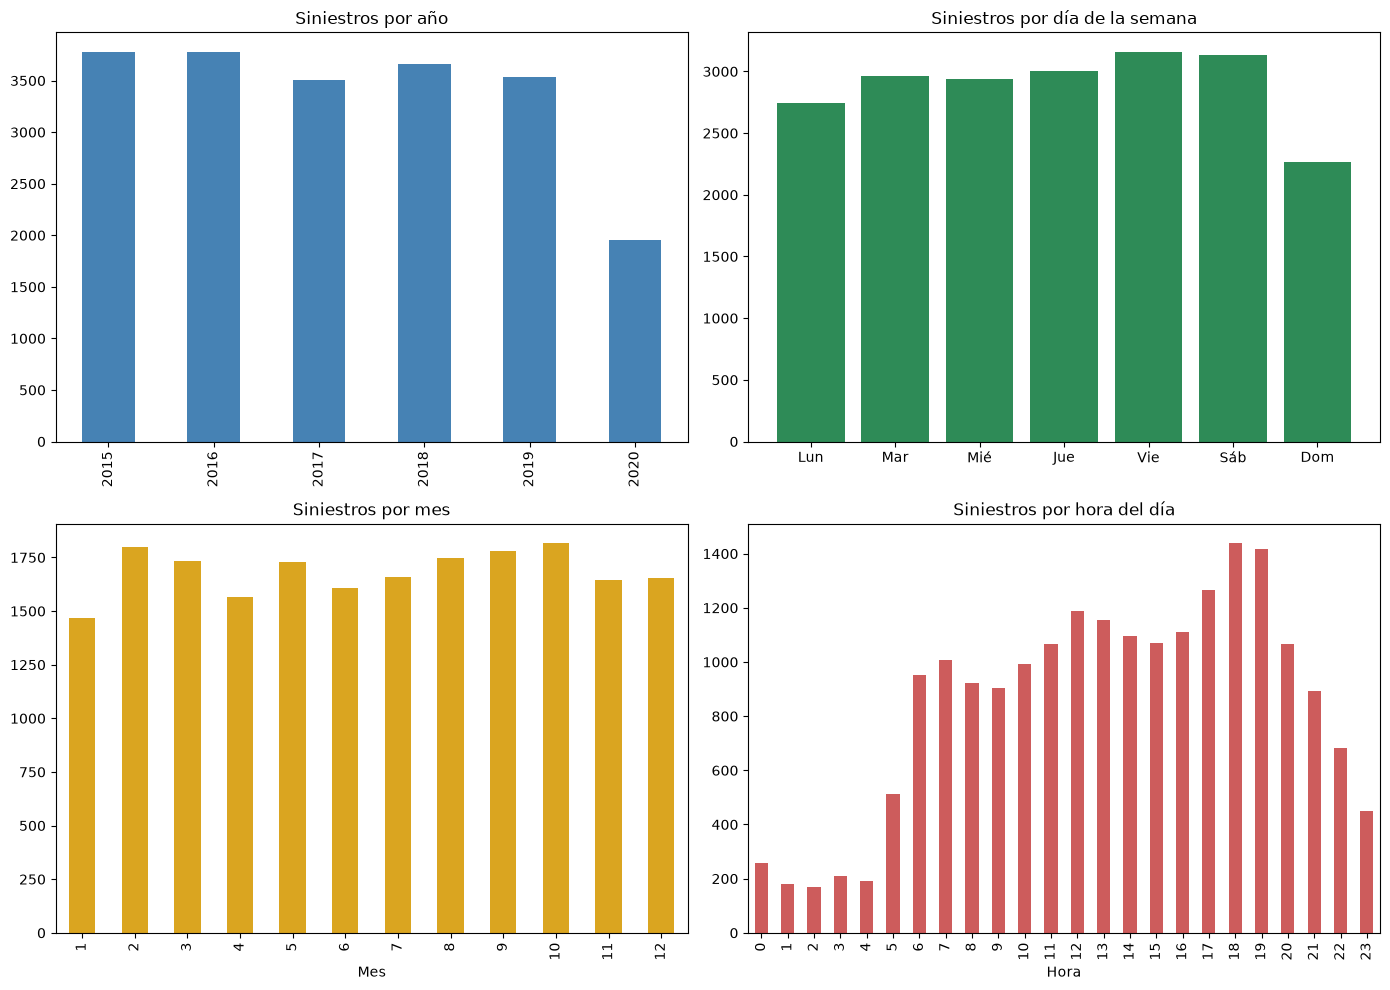

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df_peatones['ANO_OCURRENCIA_ACC'].value_counts().sort_index().plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Siniestros por año')
axes[0,0].set_xlabel('')

orden_dias = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
etiquetas_dias = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']
conteo_dias = df_peatones['DIA_SEMANA'].value_counts().reindex(orden_dias)
axes[0,1].bar(etiquetas_dias, conteo_dias.values, color='seagreen')
axes[0,1].set_title('Siniestros por día de la semana')

df_peatones['MES'].value_counts().sort_index().plot(kind='bar', ax=axes[1,0], color='goldenrod')
axes[1,0].set_title('Siniestros por mes')
axes[1,0].set_xlabel('Mes')

df_peatones['HORA_DIA'].value_counts().sort_index().plot(kind='bar', ax=axes[1,1], color='indianred')
axes[1,1].set_title('Siniestros por hora del día')
axes[1,1].set_xlabel('Hora')

plt.tight_layout()
plt.show()

**Nota:** el pico visible en el gráfico "Siniestros por año" en los últimos años puede estar afectado por el hecho de que la hoja `SINIESTROS` del Excel solo cubre hasta 2020, mientras que el CSV llega hasta 2021; esto se refleja en el porcentaje de nulos de las columnas `CHOQUE`, `OBJETO_FIJO` y `DISENO_LUGAR` para 2021.

In [19]:
tabla_cobertura = df_peatones.groupby('ANO_OCURRENCIA_ACC')['DISENO_LUGAR'].apply(lambda s: s.notna().mean() * 100).round(1)
tabla_cobertura.to_frame('pct_con_match_en_SINIESTROS')

,pct_con_match_en_SINIESTROS
ANO_OCURRENCIA_ACC,
2015,100.0
2016,100.0
2017,100.0
2018,100.0
2019,100.0
2020,100.0


## 6. Gravedad, clase de siniestro, causas y actores (siniestros con peatones)


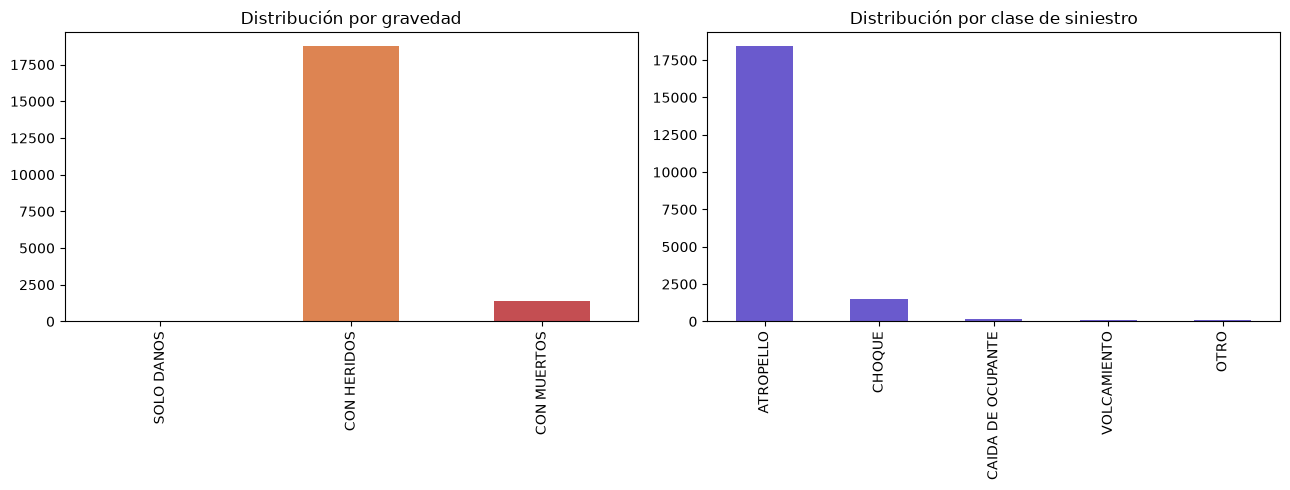

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

orden_gravedad = ['SOLO DANOS', 'CON HERIDOS', 'CON MUERTOS']
df_peatones['GRAVEDAD'].value_counts().reindex(orden_gravedad).plot(kind='bar', ax=axes[0], color=['#4c72b0','#dd8452','#c44e52'])
axes[0].set_title('Distribución por gravedad')
axes[0].set_xlabel('')

df_peatones['CLASE_ACC'].value_counts().plot(kind='bar', ax=axes[1], color='slateblue')
axes[1].set_title('Distribución por clase de siniestro')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

In [21]:
print(df_peatones['GRAVEDAD'].value_counts())
print()
print(df_peatones['CLASE_ACC'].value_counts())

GRAVEDAD
CON HERIDOS    18762
CON MUERTOS     1420
SOLO DANOS        22
Name: count, dtype: int64

CLASE_ACC
ATROPELLO            18436
CHOQUE                1477
CAIDA DE OCUPANTE      141
VOLCAMIENTO             87
OTRO                    63
Name: count, dtype: int64


### 6.1 Diseño del lugar y tipo de choque

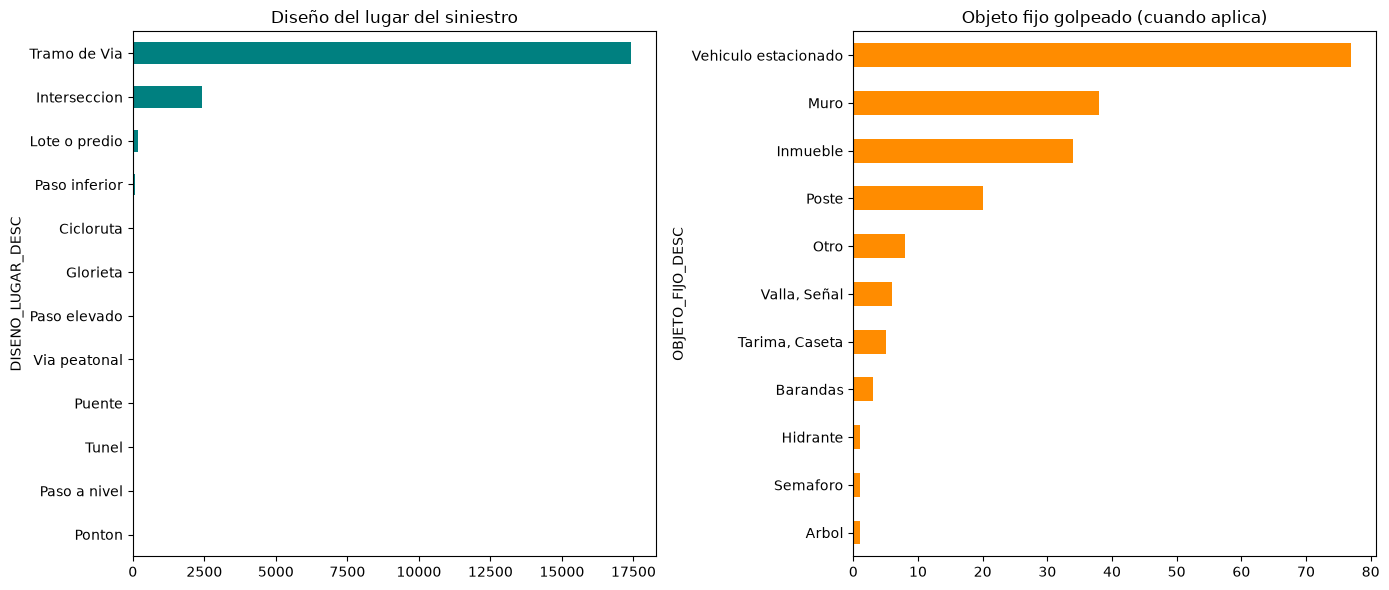

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df_peatones['DISENO_LUGAR_DESC'].value_counts().plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Diseño del lugar del siniestro')
axes[0].invert_yaxis()

df_peatones['OBJETO_FIJO_DESC'].value_counts().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Objeto fijo golpeado (cuando aplica)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### 6.2 Causas principales de los siniestros

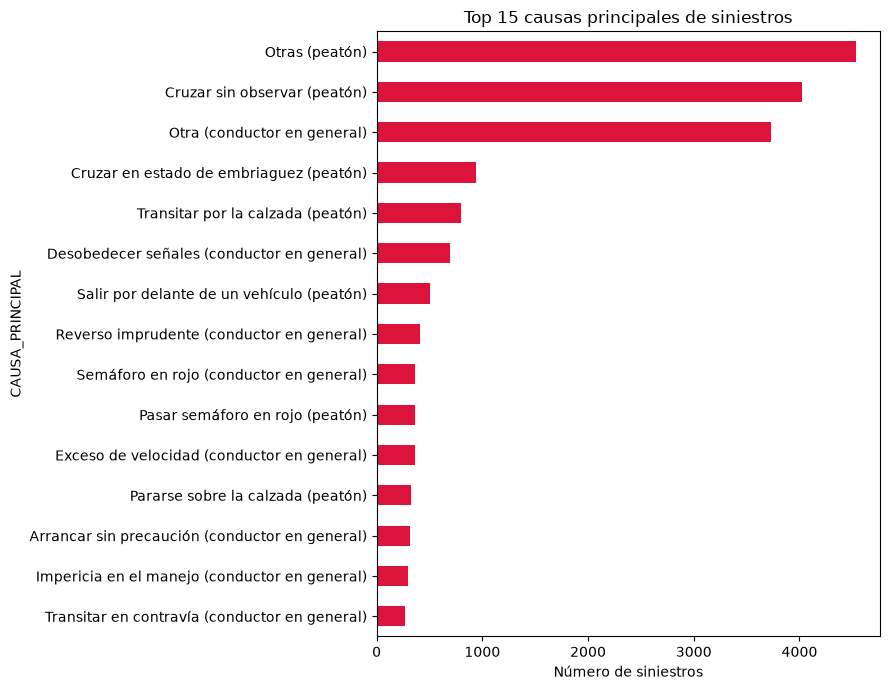

In [23]:
top_causas = df_peatones['CAUSA_PRINCIPAL'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9,7))
top_causas.sort_values().plot(kind='barh', ax=ax, color='crimson')
ax.set_title('Top 15 causas principales de siniestros')
ax.set_xlabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 6.3 Actores involucrados y clase de vehículo

--- Todos los actores del siniestro (contexto) ---
          N_ACTORES     N_MUERTOS     N_HERIDOS   N_VEHICULOS
count  20204.000000  20204.000000  20204.000000  20204.000000
mean       2.222580      0.071372      1.296129      1.079588
std        0.714646      0.262968      0.814694      0.307798
min        2.000000      0.000000      0.000000      1.000000
25%        2.000000      0.000000      1.000000      1.000000
50%        2.000000      0.000000      1.000000      1.000000
75%        2.000000      0.000000      2.000000      1.000000
max       47.000000      4.000000     44.000000      9.000000

--- Solo peatones ---
         N_PEATONES  N_PEATONES_MUERTOS  N_PEATONES_HERIDOS  N_PEATONES_ILESOS
count  20204.000000        20204.000000        20204.000000       20204.000000
mean       1.083597            0.069392            1.014106           0.000099
std        0.329377            0.257608            0.413777           0.009949
min        1.000000            0.000000            0

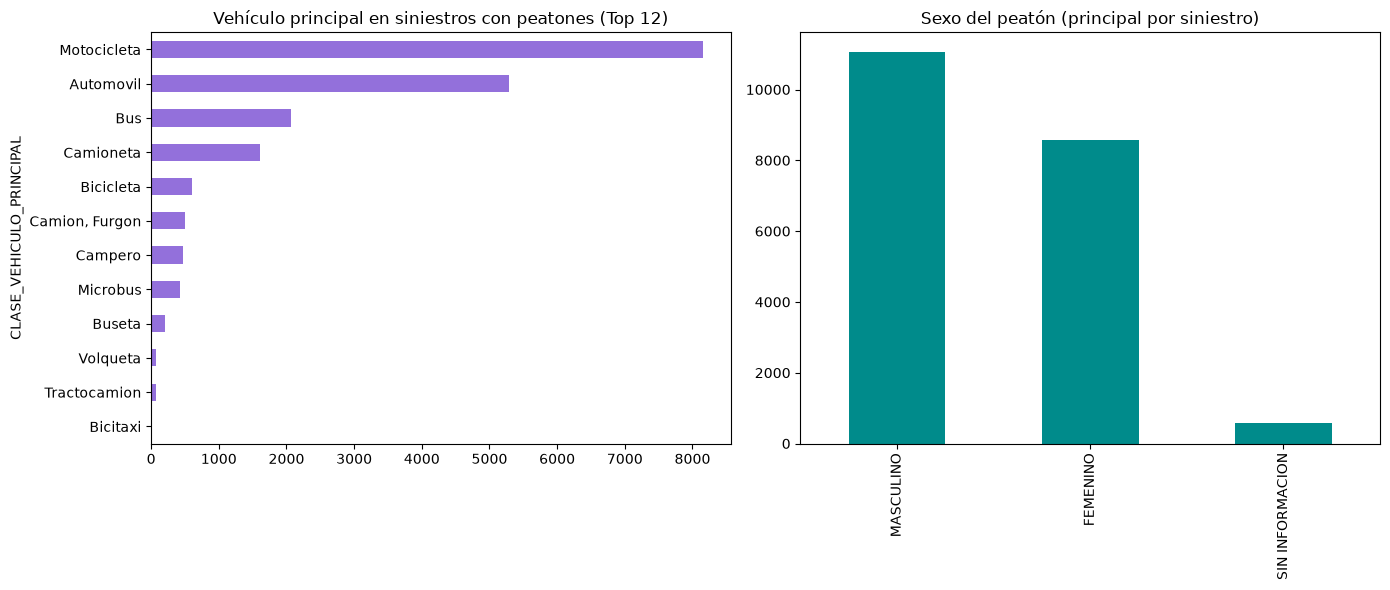

In [24]:
# N_ACTORES, N_MUERTOS, N_HERIDOS, N_VEHICULOS: cuentan a TODAS las personas/vehículos
# del siniestro (no solo peatones). Para las cifras específicas de peatones, ver N_PEATONES*.
print("--- Todos los actores del siniestro (contexto) ---")
print(df_peatones[['N_ACTORES', 'N_MUERTOS', 'N_HERIDOS', 'N_VEHICULOS']].describe())

print("\n--- Solo peatones ---")
print(df_peatones[['N_PEATONES', 'N_PEATONES_MUERTOS', 'N_PEATONES_HERIDOS', 'N_PEATONES_ILESOS']].describe())

fig, axes = plt.subplots(1, 2, figsize=(14,6))
df_peatones['CLASE_VEHICULO_PRINCIPAL'].value_counts().head(12).sort_values().plot(kind='barh', ax=axes[0], color='mediumpurple')
axes[0].set_title('Vehículo principal en siniestros con peatones (Top 12)')

df_peatones['SEXO_PEATON_PRINCIPAL'].value_counts().plot(kind='bar', ax=axes[1], color='darkcyan')
axes[1].set_title('Sexo del peatón (principal por siniestro)')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()


### 6.4 Siniestros por localidad

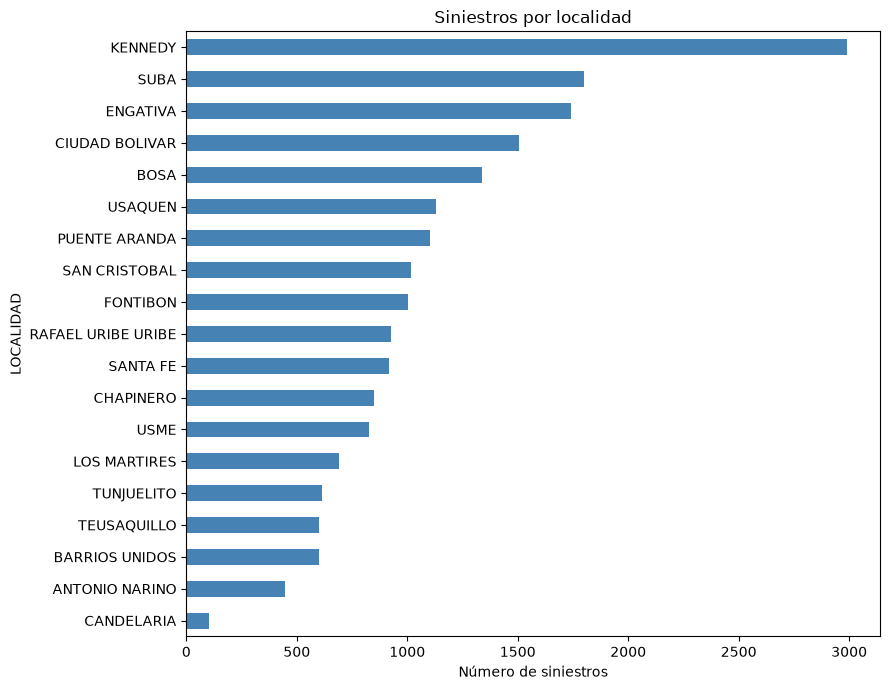

In [25]:
fig, ax = plt.subplots(figsize=(9,7))
df_peatones['LOCALIDAD'].value_counts().sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Siniestros por localidad')
ax.set_xlabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 6.5 Gravedad por localidad (tabla cruzada)

In [26]:
tabla_grav_loc = pd.crosstab(df_peatones['LOCALIDAD'], df_peatones['GRAVEDAD'])
tabla_grav_loc = tabla_grav_loc[orden_gravedad]
tabla_grav_loc['TOTAL'] = tabla_grav_loc.sum(axis=1)
tabla_grav_loc.sort_values('TOTAL', ascending=False)

GRAVEDAD,SOLO DANOS,CON HERIDOS,CON MUERTOS,TOTAL
LOCALIDAD,,,,
KENNEDY,4,2755,231,2990
SUBA,2,1695,101,1798
ENGATIVA,2,1613,124,1739
CIUDAD BOLIVAR,1,1397,108,1506
BOSA,0,1261,75,1336
USAQUEN,2,1061,67,1130
PUENTE ARANDA,1,1005,99,1105
SAN CRISTOBAL,0,957,62,1019
FONTIBON,2,928,72,1002


## 7. Mapa de zonas con siniestros que involucran peatones

Se usan las coordenadas `LATITUD`/`LONGITUD` del CSV (presentes en el 100% de los registros) para construir:

1. Un mapa de puntos coloreado por gravedad.
2. Un mapa de densidad (hexbin) que resalta las **zonas con mayor concentración de siniestros**.
3. Un mapa de densidad exclusivo para siniestros **con muertos**, al ser el subconjunto de mayor interés para política pública.

In [27]:
coords_validas = df_peatones[['LATITUD','LONGITUD']].notna().all(axis=1).sum()
print(f"Registros con coordenadas válidas: {coords_validas:,} de {len(df_peatones):,} ({coords_validas/len(df_peatones)*100:.1f}%)")
print()
print(df_peatones[['LATITUD','LONGITUD']].describe())

Registros con coordenadas válidas: 20,204 de 20,204 (100.0%)

            LATITUD      LONGITUD
count  20204.000000  20204.000000
mean       4.632424    -74.113333
std        0.062002      0.040413
min        4.085800    -74.228300
25%        4.589935    -74.142951
50%        4.624243    -74.111747
75%        4.678347    -74.084410
max        4.818734    -74.014053


### 7.0 Recorte a la zona urbana

Un pequeño número de registros (~13 de 199.146) tiene coordenadas muy alejadas del área urbana de Bogotá (zonas rurales del sur / posibles errores de geocodificación). Al graficarlos, estiran la escala del mapa y dificultan ver el detalle de la ciudad. Se acotan los ejes a la zona urbana para los mapas siguientes; el dataset `df_peatones` **no se filtra**, solo se ajusta la vista.

In [28]:
LON_MIN, LON_MAX = -74.24, -73.99
LAT_MIN, LAT_MAX = 4.45, 4.84

fuera_de_rango = (~df_peatones['LONGITUD'].between(LON_MIN, LON_MAX)) | (~df_peatones['LATITUD'].between(LAT_MIN, LAT_MAX))
print(f"Registros fuera de la zona urbana acotada: {fuera_de_rango.sum()} de {len(df_peatones)}")

Registros fuera de la zona urbana acotada: 1 de 20204


### 7.1 Mapa de puntos por gravedad

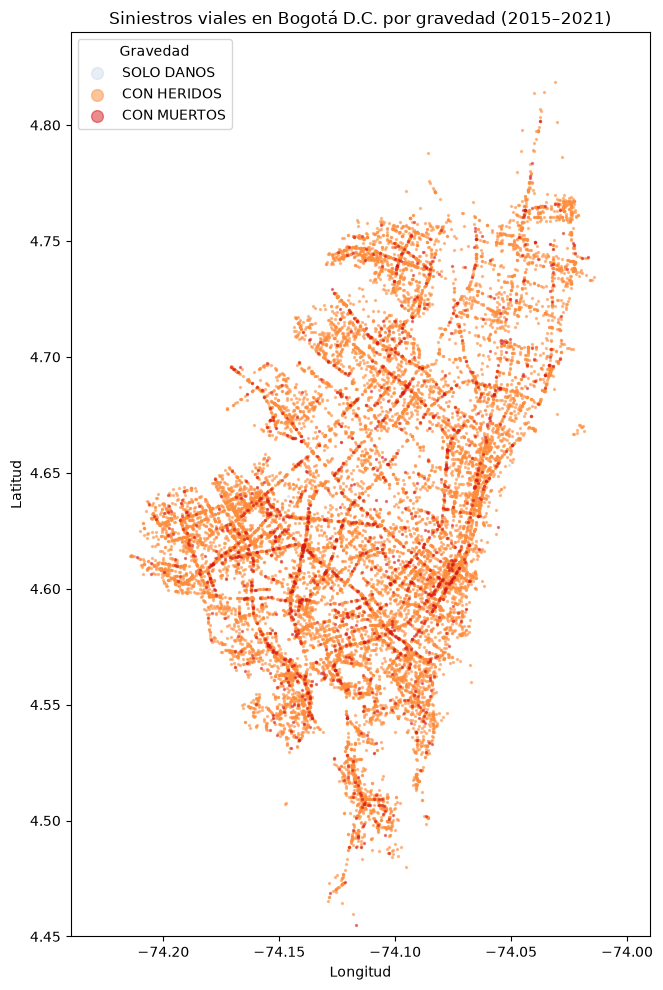

In [29]:
fig, ax = plt.subplots(figsize=(9, 10))

colores = {'SOLO DANOS': '#a6bddb', 'CON HERIDOS': '#fd8d3c', 'CON MUERTOS': '#d7191c'}
orden_plot = ['SOLO DANOS', 'CON HERIDOS', 'CON MUERTOS']  # dibujar muertos al final (encima)

for grav in orden_plot:
    sub = df_peatones[df_peatones['GRAVEDAD'] == grav]
    ax.scatter(sub['LONGITUD'], sub['LATITUD'], s=2, alpha=0.25 if grav=='SOLO DANOS' else 0.5,
               color=colores[grav], label=grav)

ax.set_title('Siniestros viales en Bogotá D.C. por gravedad (2015–2021)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
leg = ax.legend(markerscale=6, title='Gravedad')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

### 7.2 Mapa de densidad (zonas con mayor concentración de siniestros)

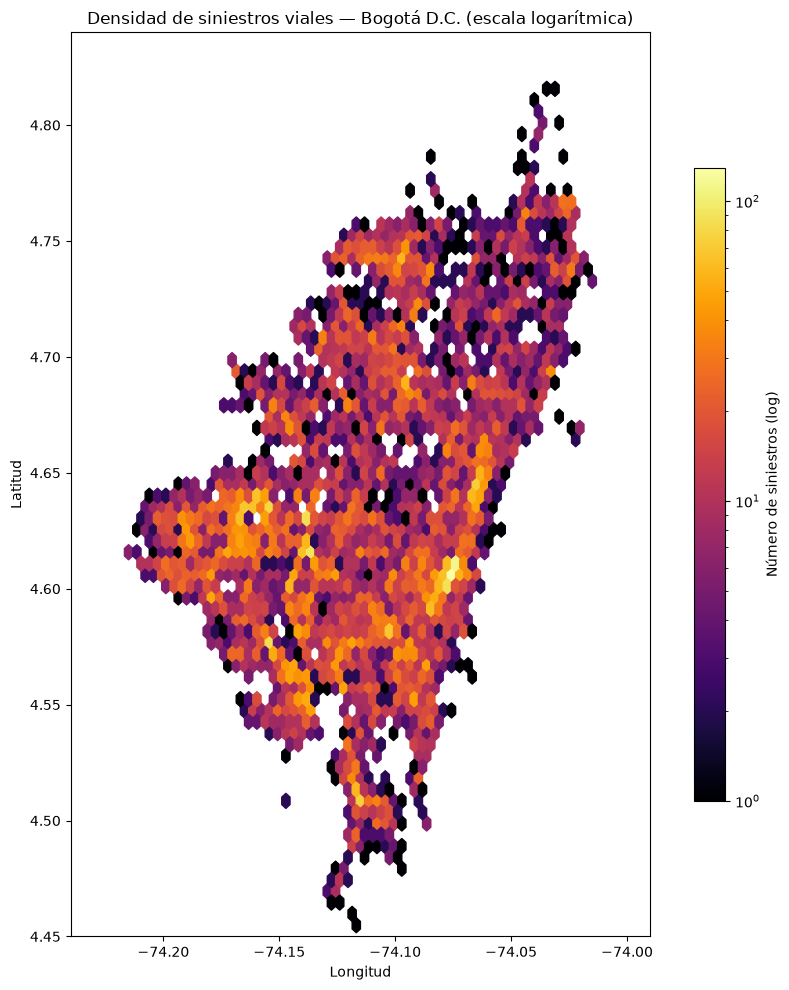

In [30]:
fig, ax = plt.subplots(figsize=(9, 10))

hb = ax.hexbin(df_peatones['LONGITUD'], df_peatones['LATITUD'], gridsize=70, cmap='inferno', mincnt=1, bins='log',
               extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_title('Densidad de siniestros viales — Bogotá D.C. (escala logarítmica)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label('Número de siniestros (log)')
plt.tight_layout()
plt.show()

### 7.3 Mapa de densidad — solo siniestros con muertos

Siniestros con muertos: 1,420


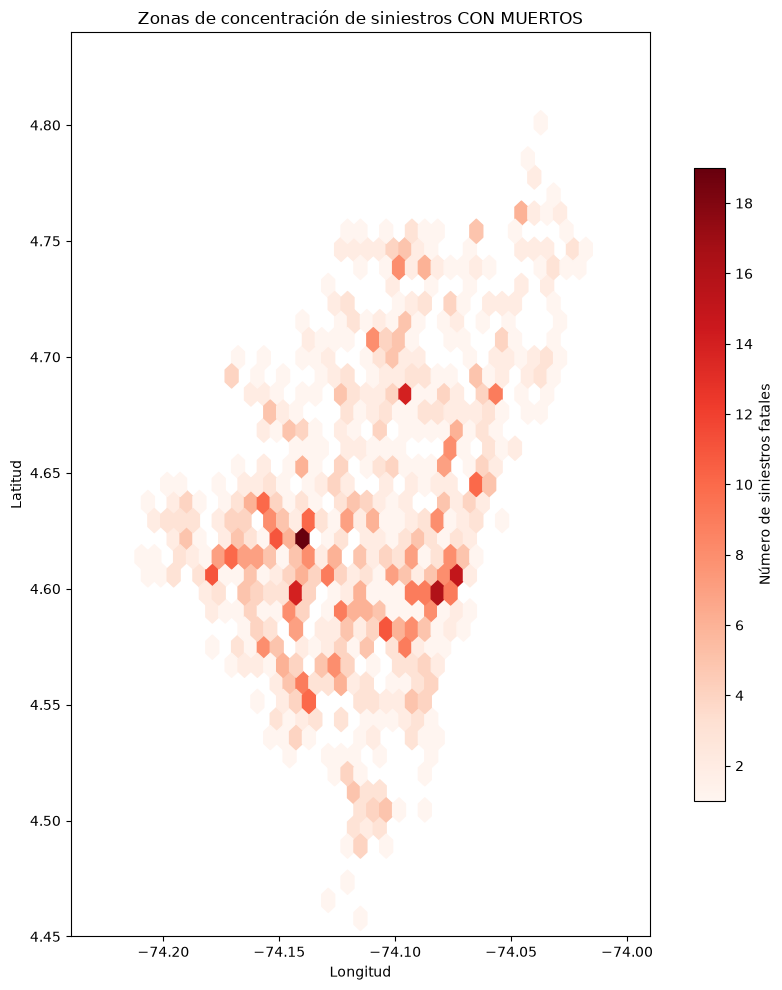

In [31]:
fatales = df_peatones[df_peatones['GRAVEDAD'] == 'CON MUERTOS']
print(f"Siniestros con muertos: {len(fatales):,}")

fig, ax = plt.subplots(figsize=(9, 10))
hb = ax.hexbin(fatales['LONGITUD'], fatales['LATITUD'], gridsize=45, cmap='Reds', mincnt=1,
               extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_title('Zonas de concentración de siniestros CON MUERTOS')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label('Número de siniestros fatales')
plt.tight_layout()
plt.show()

### 7.4 Top 10 direcciones con más siniestros

Complementa el mapa identificando los puntos exactos (direcciones) más críticos.

In [32]:
df_peatones['DIRECCION'].value_counts().head(10).to_frame('N_SINIESTROS')

,N_SINIESTROS
DIRECCION,
KR 80-CL 2 51,41
AV AVENIDA CARACAS-CL 22 02,23
KR 80-CL 2 S 51,21
AV AVENIDA CARACAS-CL 40 S 02,17
KR 10-CL 13 02,13
AV AVENIDA BOYACA-AV AVENIDA PRIMERO DE MAYO 02,13
AV AVENIDA CARACAS-CL 60 02,13
AV AVENIDA CARACAS-CL 19 02,12
AV AVENIDA BOYACA-CL 53 02,12


## 8. Resumen y hallazgos clave

**Corrección de alcance**

- El EDA de esta versión corre sobre `df_peatones`: siniestros donde `ACTOR_VIAL.CONDICION == 'PEATON'` para al menos una persona, obtenido con un `inner join` entre el dataset general y la agregación `agg_peatones`.
- Las columnas `N_ACTORES`, `N_MUERTOS`, `N_HERIDOS`, `N_VEHICULOS` y `CLASE_VEHICULO_PRINCIPAL` siguen describiendo a **todas** las personas/vehículos del siniestro (útil como contexto); las cifras específicas de peatones están en `N_PEATONES`, `N_PEATONES_MUERTOS`, `N_PEATONES_HERIDOS`, `N_PEATONES_ILESOS` y `SEXO_PEATON_PRINCIPAL`.

**Pendiente al ejecutar**

- Los hallazgos numéricos de la versión anterior (recuento por año, por localidad, causas top, etc.) correspondían a **todos** los siniestros y ya no aplican a `df_peatones`. Vuelve a leerlos tras ejecutar el cuaderno con los datos reales para obtener las cifras correctas del subconjunto peatonal.
- Presta especial atención a: proporción de siniestros con muertos/heridos dentro de `df_peatones` (suele ser mayor que en el total de siniestros), localidades y horas con más siniestros peatonales, y causas principales (`CAUSA_PRINCIPAL`) más frecuentes en este subconjunto.

**Limitaciones**

1. `CAUSA_PRINCIPAL` proviene de `HIPOTESIS` y no está filtrada por actor: puede incluir causas atribuidas a otros actores del mismo siniestro (p. ej. exceso de velocidad de un conductor), no solo causas atribuibles al peatón. Si se necesita aislar causas peatonales, hay que cruzar con los códigos de `CODIGO_CAUSA` agrupados como "peatón" en el diccionario.
2. El campo `EDAD` en `ACTOR_VIAL` contiene inconsistencias de formato y debe limpiarse antes de análisis demográfico de los peatones.
3. El desbalance temporal entre fuentes (Excel hasta 2020, CSV hasta 2021) sigue aplicando a `df_peatones`.


## 9. Salida final

In [33]:
df_peatones.head()


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC,N_ACTORES,N_MUERTOS,N_HERIDOS,N_VEHICULOS,CLASE_VEHICULO_PRINCIPAL,CAUSA_PRINCIPAL,N_PEATONES,N_PEATONES_MUERTOS,N_PEATONES_HERIDOS,N_PEATONES_ILESOS,SEXO_PEATON_PRINCIPAL,MES,DIA_SEMANA,HORA_DIA
0,-74.042000,4.778000,9,A001179874,10533587,2020-08-03 00:00:00+00:00,2020,AU NORTE - CL 200 02,CON MUERTOS,ATROPELLO,SUBA,2020-08-03 14:05:00+00:00,4.778000,-74.042000,1006455.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Camioneta,Otra (conductor en general),1,1,0,0,MASCULINO,8,Monday,14
1,-74.110585,4.693578,13,A000551010,4468708,2016-12-27 00:00:00+00:00,2016,CL 69A-KR 89A 02,CON HERIDOS,CHOQUE,ENGATIVA,2016-12-27 19:00:00+00:00,4.693578,-74.110585,10006813.0,219627.0,1.0,Vehiculo,NaN,NaN,2.0,Interseccion,3.0,0.0,2.0,2.0,Automovil,Desobedecer señales (conductor en general),1,0,1,0,MASCULINO,12,Tuesday,19
2,-74.113000,4.508000,18,A001180302,10533662,2020-09-14 00:00:00+00:00,2020,KR 12 - CL 81 S 52,CON MUERTOS,ATROPELLO,USME,2020-09-14 21:30:00+00:00,4.508000,-74.113000,5003431.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Motocicleta,Otra (conductor en general),1,1,0,0,SIN INFORMACION,9,Monday,21
3,-74.077000,4.660000,23,A001180467,10533606,2020-08-22 00:00:00+00:00,2020,KR 30 - CL 64 48,CON MUERTOS,ATROPELLO,BARRIOS UNIDOS,2020-08-22 19:45:00+00:00,4.660000,-74.077000,12002271.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Automovil,Otra (conductor en general),1,1,0,0,MASCULINO,8,Saturday,19
4,-74.113000,4.574000,29,A001236422,10530927,2020-12-24 00:00:00+00:00,2020,TV 13 BIS A - CL 32 S 02,CON HERIDOS,ATROPELLO,RAFAEL URIBE URIBE,2020-12-24 08:55:00+00:00,4.574000,-74.113000,18002038.0,NaN,NaN,NaN,NaN,NaN,2.0,Interseccion,2.0,0.0,1.0,1.0,Automovil,NaN,1,0,1,0,MASCULINO,12,Thursday,8


In [34]:
import geopandas as gpd
df_peatones = gpd.GeoDataFrame(
    df_peatones,  # o el DataFrame que estés procesando
    geometry=gpd.points_from_xy(df_peatones.LONGITUD, df_peatones.LATITUD),  # Cambia por los nombres exactos de tus columnas
    crs="EPSG:4326"
)


## Verificacion de nulos

In [35]:
print("Nulos en geometry (siniestraliedad):", df_peatones.geometry.isna().sum())

Nulos en geometry (siniestraliedad): 0


In [36]:
df_peatones = df_peatones.to_crs(epsg=3116)
print("CRS siniestralidad (peatones):", df_peatones.crs)


CRS siniestralidad (peatones): EPSG:3116


In [37]:
# os.makedirs('Data/processed', exist_ok=True)
# df_peatones.to_file('Data/processed/siniestros_peatones_procesados.gpkg', driver='GPKG')

# print('Guardado: Data/processed/siniestros_peatones_procesados.gpkg', df_peatones.shape)


In [38]:
df_peatones

,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC,N_ACTORES,N_MUERTOS,N_HERIDOS,N_VEHICULOS,CLASE_VEHICULO_PRINCIPAL,CAUSA_PRINCIPAL,N_PEATONES,N_PEATONES_MUERTOS,N_PEATONES_HERIDOS,N_PEATONES_ILESOS,SEXO_PEATON_PRINCIPAL,MES,DIA_SEMANA,HORA_DIA,geometry
0,-74.042000,4.778000,9,A001179874,10533587,2020-08-03 00:00:00+00:00,2020,AU NORTE - CL 200 02,CON MUERTOS,ATROPELLO,SUBA,2020-08-03 14:05:00+00:00,4.778000,-74.042000,1006455.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Camioneta,Otra (conductor en general),1,1,0,0,MASCULINO,8,Monday,14,POINT (1003939.079 1020103.807)
1,-74.110585,4.693578,13,A000551010,4468708,2016-12-27 00:00:00+00:00,2016,CL 69A-KR 89A 02,CON HERIDOS,CHOQUE,ENGATIVA,2016-12-27 19:00:00+00:00,4.693578,-74.110585,10006813.0,219627.0,1.0,Vehiculo,NaN,NaN,2.0,Interseccion,3.0,0.0,2.0,2.0,Automovil,Desobedecer señales (conductor en general),1,0,1,0,MASCULINO,12,Tuesday,19,POINT (996330.145 1010768.302)
2,-74.113000,4.508000,18,A001180302,10533662,2020-09-14 00:00:00+00:00,2020,KR 12 - CL 81 S 52,CON MUERTOS,ATROPELLO,USME,2020-09-14 21:30:00+00:00,4.508000,-74.113000,5003431.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Motocicleta,Otra (conductor en general),1,1,0,0,SIN INFORMACION,9,Monday,21,POINT (996061.18 990246.782)
3,-74.077000,4.660000,23,A001180467,10533606,2020-08-22 00:00:00+00:00,2020,KR 30 - CL 64 48,CON MUERTOS,ATROPELLO,BARRIOS UNIDOS,2020-08-22 19:45:00+00:00,4.660000,-74.077000,12002271.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Automovil,Otra (conductor en general),1,1,0,0,MASCULINO,8,Saturday,19,POINT (1000056.355 1007055.054)
4,-74.113000,4.574000,29,A001236422,10530927,2020-12-24 00:00:00+00:00,2020,TV 13 BIS A - CL 32 S 02,CON HERIDOS,ATROPELLO,RAFAEL URIBE URIBE,2020-12-24 08:55:00+00:00,4.574000,-74.113000,18002038.0,NaN,NaN,NaN,NaN,NaN,2.0,Interseccion,2.0,0.0,1.0,1.0,Automovil,NaN,1,0,1,0,MASCULINO,12,Thursday,8,POINT (996061.538 997545.145)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20199,-74.044200,4.763300,410314,A000640834,4485790,2017-06-23 00:00:00+00:00,2017,KR 45-CL 185 02,CON MUERTOS,ATROPELLO,USAQUEN,2017-06-23 07:20:00+00:00,4.763300,-74.044200,0.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Camioneta,Transitar por la calzada (peatón),1,1,0,0,SIN INFORMACION,6,Friday,7,POINT (1003695.1 1018478.24)
20200,-74.129900,4.608000,410357,A000554455,4471631,2017-02-03 00:00:00+00:00,2017,AK 68-CL 29 S 02,CON MUERTOS,ATROPELLO,KENNEDY,2017-02-03 18:24:00+00:00,4.608000,-74.129900,8009975.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,3.0,1.0,1.0,1.0,Automovil,Otra (conductor en general),2,1,1,0,FEMENINO,2,Friday,18,POINT (994186.465 1001305.028)
20201,-74.079100,4.598200,410404,A000695360,4505065,2017-12-17 00:00:00+00:00,2017,KR 10-CL 9 15,CON MUERTOS,ATROPELLO,CANDELARIA,2017-12-17 22:00:00+00:00,4.598200,-74.079100,3000803.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Automovil,Otra (conductor en general),1,1,0,0,MASCULINO,12,Sunday,22,POINT (999823.337 1000221.117)
20202,-74.121100,4.556500,410493,A000819692,10454272,2018-07-15 00:00:00+00:00,2018,KR 7-CL 50A S 33,CON MUERTOS,ATROPELLO,RAFAEL URIBE URIBE,2018-07-15 00:05:00+00:00,4.556500,-74.121100,18004760.0,NaN,NaN,NaN,NaN,NaN,1.0,Tramo de Via,2.0,1.0,0.0,1.0,Bus,Otra (conductor en general),1,1,0,0,MASCULINO,7,Sunday,0,POINT (995162.586 995610.021)
